<a href="https://colab.research.google.com/github/KunderLavanya/mental_health_analysis/blob/main/Mental_Health.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mental Health Dataset

In [ ]:
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

KeyboardInterrupt: 

In [ ]:
import pandas as pd

df = pd.read_csv('Mental Health Dataset.csv')
display(df.head())

Understanding the Dataset

In [ ]:
df

In [ ]:
df.head()

In [ ]:
df.describe()

In [ ]:
df.info()

In [ ]:
df.shape

In [ ]:
print(df.columns.tolist())

Data Preprocessing

In [ ]:
df.isnull().sum()

In [ ]:
df.duplicated().sum()

# **Mental Analysis EDA**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import ( train_test_split,cross_val_score,KFold,StratifiedKFold)

from sklearn.preprocessing import (StandardScaler,MinMaxScaler,RobustScaler,OneHotEncoder, OrdinalEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import (
    SelectKBest,
    mutual_info_regression,
    mutual_info_classif
)

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid", palette="viridis")

RANDOM_STATE = 42

In [ ]:


df = pd.read_csv("/content/enhanced_anxiety_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst Five Records:")
display(df.head())

print("\nLast Five Records:")
display(df.tail())

print("\nRandom Samples:")
display(df.sample(10, random_state=RANDOM_STATE))

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (11000, 19)

First Five Records:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
0,29,Female,Artist,6.0,2.7,181,10,Yes,No,10,114,14,4,No,Yes,3,Yes,7,5.0
1,46,Other,Nurse,6.2,5.7,200,8,Yes,Yes,1,62,23,2,Yes,No,2,No,8,3.0
2,64,Male,Other,5.0,3.7,117,4,No,Yes,1,91,28,3,No,No,1,Yes,1,1.0
3,20,Female,Scientist,5.8,2.8,360,6,Yes,No,4,86,17,3,No,No,0,No,1,2.0
4,49,Female,Other,8.2,2.3,247,4,Yes,No,1,98,19,4,Yes,Yes,1,No,3,1.0



Last Five Records:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
10995,23,Female,Engineer,6.1,3.1,566,9,Yes,No,8,91,28,1,Yes,Yes,1,No,3,6.0
10996,50,Other,Teacher,6.6,3.6,64,17,Yes,No,7,95,17,3,No,No,2,No,7,3.0
10997,29,Male,Nurse,6.7,6.9,159,14,No,No,8,72,16,1,Yes,Yes,2,Yes,7,4.0
10998,53,Other,Artist,5.7,2.7,248,8,No,No,4,112,28,3,Yes,Yes,1,Yes,2,4.0
10999,56,Other,Teacher,6.1,1.1,205,11,No,No,1,66,13,3,No,No,2,Yes,8,2.0



Random Samples:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),Heart Rate (bpm),Breathing Rate (breaths/min),Sweating Level (1-5),Dizziness,Medication,Therapy Sessions (per month),Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10)
107,35,Female,Engineer,7.7,4.6,561,8,No,No,10,87,27,2,No,No,2,No,9,5.0
5484,42,Other,Teacher,6.3,5.4,208,17,Yes,No,10,82,25,1,No,Yes,0,Yes,4,5.0
6998,46,Male,Scientist,5.4,0.2,367,9,No,Yes,9,93,25,3,Yes,No,6,No,2,10.0
3984,23,Female,Student,6.7,1.1,290,3,Yes,No,1,74,18,2,No,Yes,0,No,9,1.0
3111,26,Male,Teacher,6.4,3.8,36,4,Yes,Yes,3,115,26,4,No,Yes,4,No,8,1.0
4040,44,Male,Freelancer,7.5,2.6,128,8,Yes,No,2,64,24,1,No,No,0,Yes,1,3.0
3013,21,Other,Nurse,6.5,1.1,274,18,Yes,No,10,78,26,4,No,No,2,No,10,4.0
6607,57,Female,Scientist,5.8,2.9,312,5,No,No,5,70,25,4,No,Yes,1,No,6,5.0
4219,40,Female,Lawyer,6.0,1.9,466,2,Yes,No,3,113,17,5,Yes,No,2,Yes,1,4.0
8750,25,Male,Doctor,5.9,2.7,461,14,No,No,7,60,15,5,Yes,No,0,No,2,4.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                11000 non-null  int64  
 1   Gender                             11000 non-null  object 
 2   Occupation                         11000 non-null  object 
 3   Sleep Hours                        11000 non-null  float64
 4   Physical Activity (hrs/week)       11000 non-null  float64
 5   Caffeine Intake (mg/day)           11000 non-null  int64  
 6   Alcohol Consumption (drinks/week)  11000 non-null  int64  
 7   Smoking                            11000 non-null  object 
 8   Family History of Anxiety          11000 non-null  object 
 9   Stress Level (1-10)                11000 non-null  int64  
 10  Heart Rate (bpm)                   11000 non-null  int64  
 11  Breathing Rate (breaths/min)    

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,11000.0,NaN,NaN,NaN,40.241727,13.23614,18.0,29.0,40.0,51.0,64.0
Gender,11000,3,Female,3730,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,11000,13,Musician,892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Hours,11000.0,NaN,NaN,NaN,6.650691,1.227509,2.3,5.9,6.7,7.5,11.3
Physical Activity (hrs/week),11000.0,NaN,NaN,NaN,2.942136,1.827825,0.0,1.5,2.8,4.2,10.1
Caffeine Intake (mg/day),11000.0,NaN,NaN,NaN,286.09,144.813157,0.0,172.0,273.0,382.0,599.0
Alcohol Consumption (drinks/week),11000.0,NaN,NaN,NaN,9.701636,5.689713,0.0,5.0,10.0,15.0,19.0
Smoking,11000,2,Yes,5779,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family History of Anxiety,11000,2,Yes,5847,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Stress Level (1-10),11000.0,NaN,NaN,NaN,5.856364,2.927202,1.0,3.0,6.0,8.0,10.0


In [ ]:

print("\nMissing Values:")
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})
display(missing)

print("\nDuplicate Records:", df.duplicated().sum())

print("\nUnique Values:")
display(df.nunique().to_frame("Unique_Count"))

print("\nData Types:")
display(df.dtypes.to_frame("Data_Type"))

print("\nConstant Columns:")
constant_columns = [
    col for col in df.columns if df[col].nunique() <= 1
]
print(constant_columns)

print("\nWhitespace Check:")
for col in df.select_dtypes(include="object"):
    print(col, df[col].astype(str).str.strip().ne(df[col]).sum())





Missing Values:


,Missing_Count,Missing_Percentage
Age,0,0.0
Gender,0,0.0
Occupation,0,0.0
Sleep Hours,0,0.0
Physical Activity (hrs/week),0,0.0
Caffeine Intake (mg/day),0,0.0
Alcohol Consumption (drinks/week),0,0.0
Smoking,0,0.0
Family History of Anxiety,0,0.0
Stress Level (1-10),0,0.0



Duplicate Records: 0

Unique Values:


,Unique_Count
Age,47
Gender,3
Occupation,13
Sleep Hours,82
Physical Activity (hrs/week),100
Caffeine Intake (mg/day),600
Alcohol Consumption (drinks/week),20
Smoking,2
Family History of Anxiety,2
Stress Level (1-10),10



Data Types:


,Data_Type
Age,int64
Gender,object
Occupation,object
Sleep Hours,float64
Physical Activity (hrs/week),float64
Caffeine Intake (mg/day),int64
Alcohol Consumption (drinks/week),int64
Smoking,object
Family History of Anxiety,object
Stress Level (1-10),int64



Constant Columns:
[]

Whitespace Check:
Gender 0
Occupation 0
Smoking 0
Family History of Anxiety 0
Dizziness 0
Medication 0
Recent Major Life Event 0


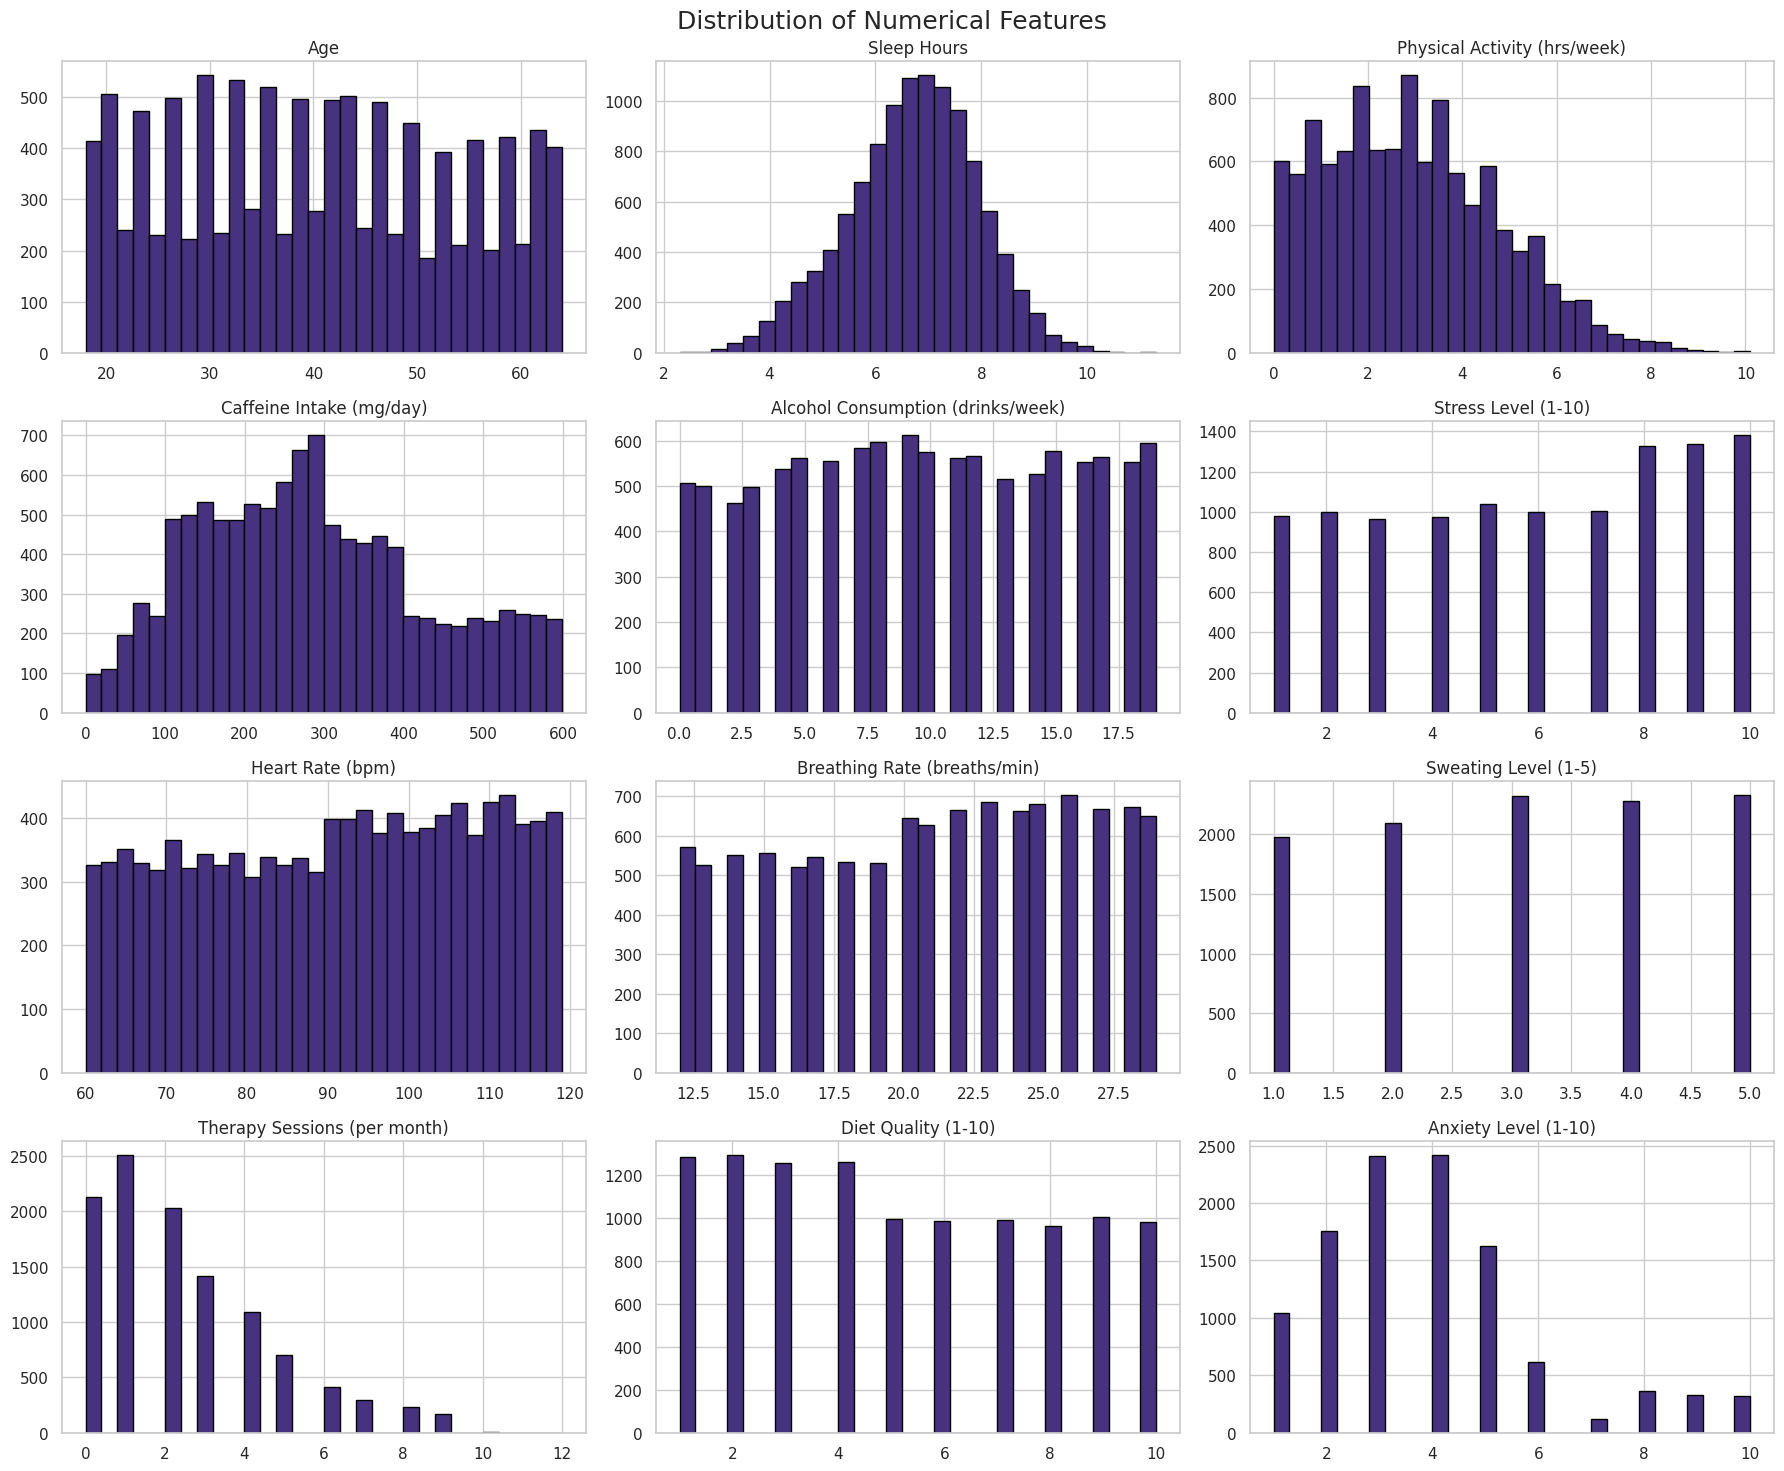

In [ ]:

numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

df[numerical_cols].hist(
    figsize=(18, 15),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=18)
plt.tight_layout()
plt.show()





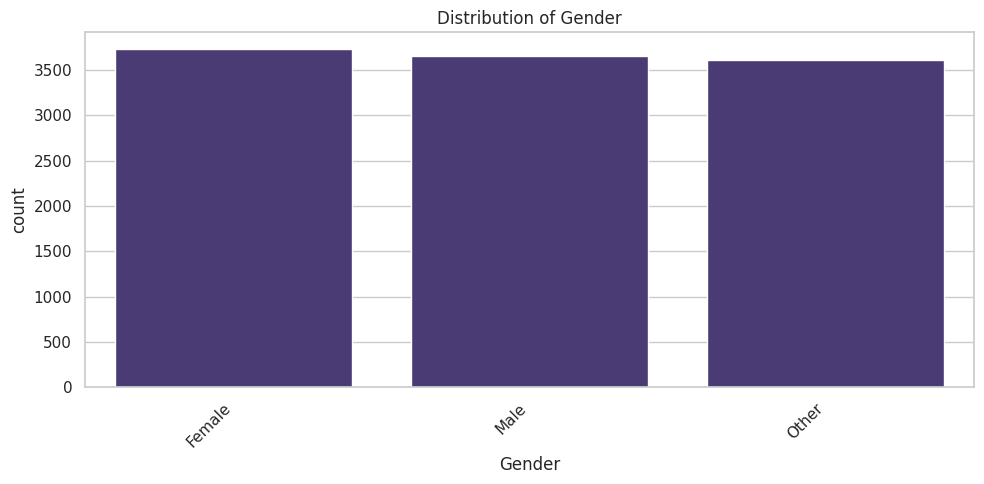


Frequency Distribution: Gender


,Count
Gender,
Female,3730
Male,3657
Other,3613


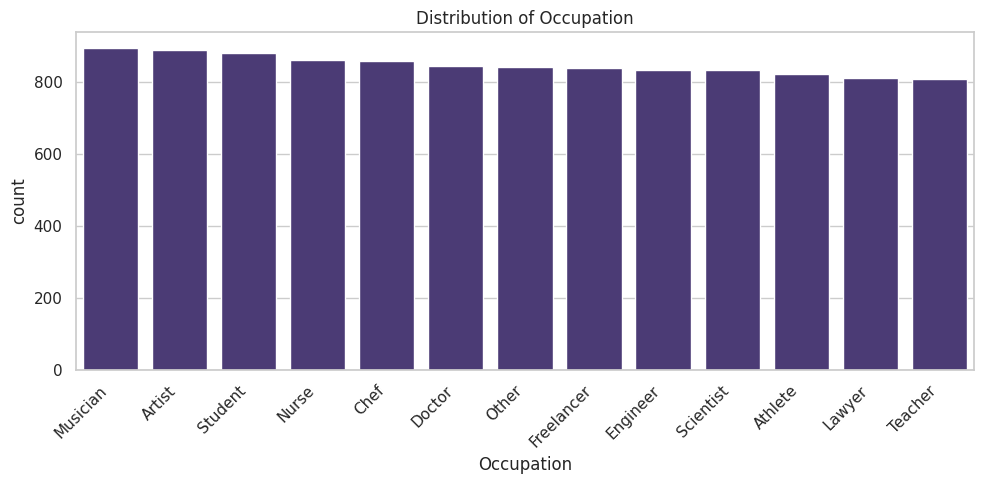


Frequency Distribution: Occupation


,Count
Occupation,
Musician,892
Artist,888
Student,878
Nurse,861
Chef,858
Doctor,842
Other,840
Freelancer,838
Engineer,833


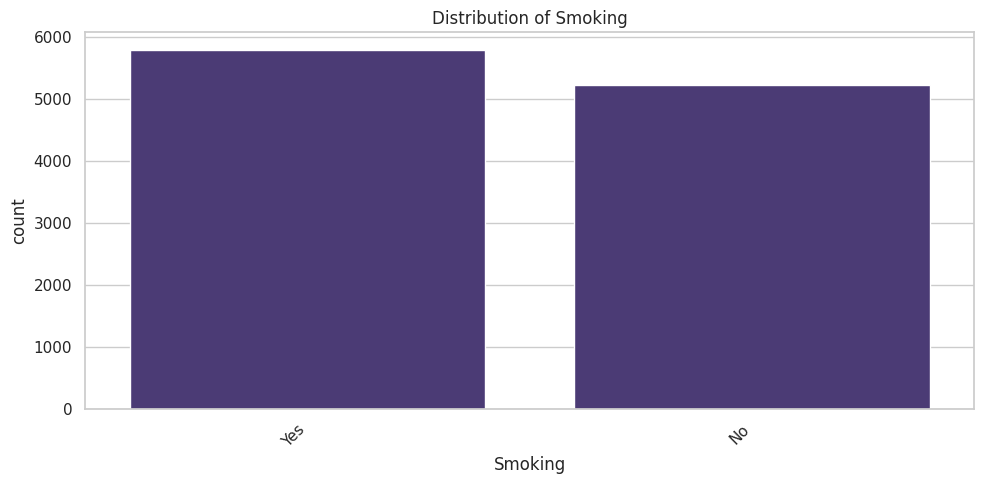


Frequency Distribution: Smoking


,Count
Smoking,
Yes,5779
No,5221


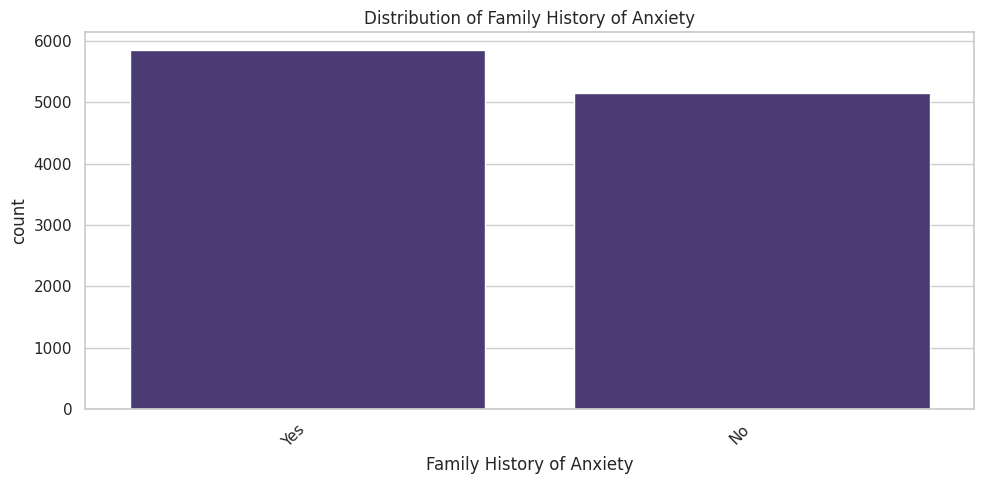


Frequency Distribution: Family History of Anxiety


,Count
Family History of Anxiety,
Yes,5847
No,5153


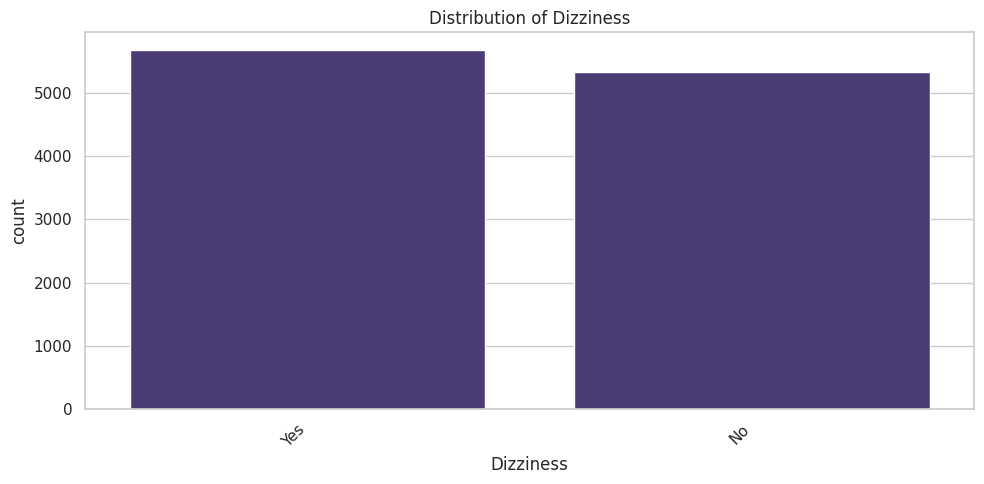


Frequency Distribution: Dizziness


,Count
Dizziness,
Yes,5672
No,5328


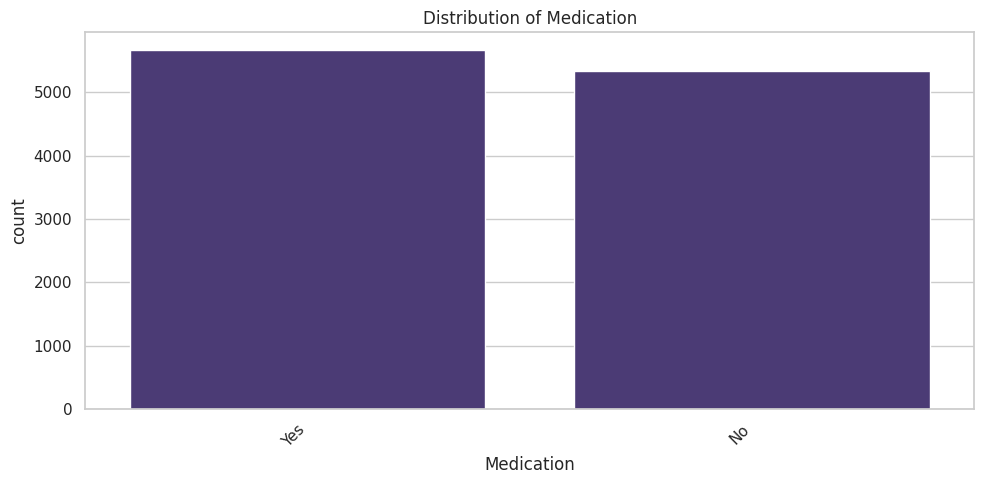


Frequency Distribution: Medication


,Count
Medication,
Yes,5666
No,5334


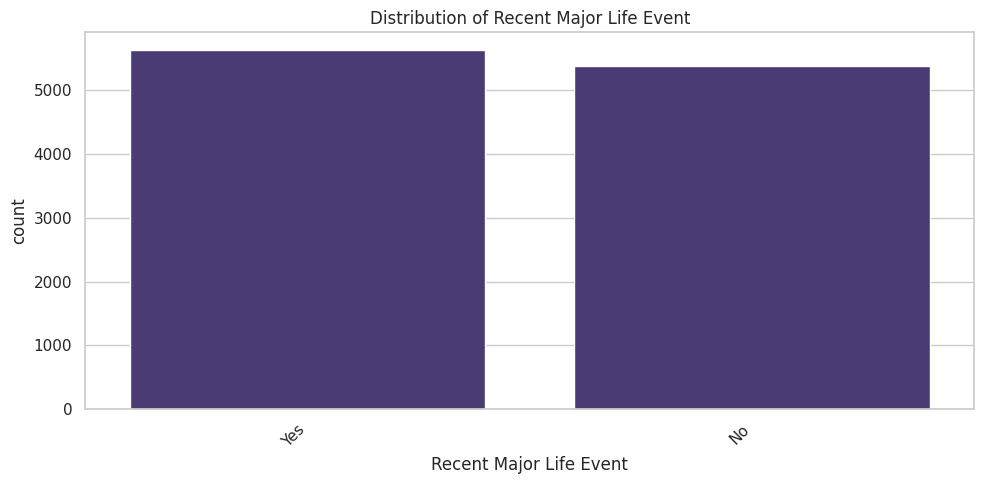


Frequency Distribution: Recent Major Life Event


,Count
Recent Major Life Event,
Yes,5623
No,5377


In [ ]:


categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    order = df[col].value_counts().index

    sns.countplot(
        data=df,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"\nFrequency Distribution: {col}")
    display(df[col].value_counts().to_frame("Count"))

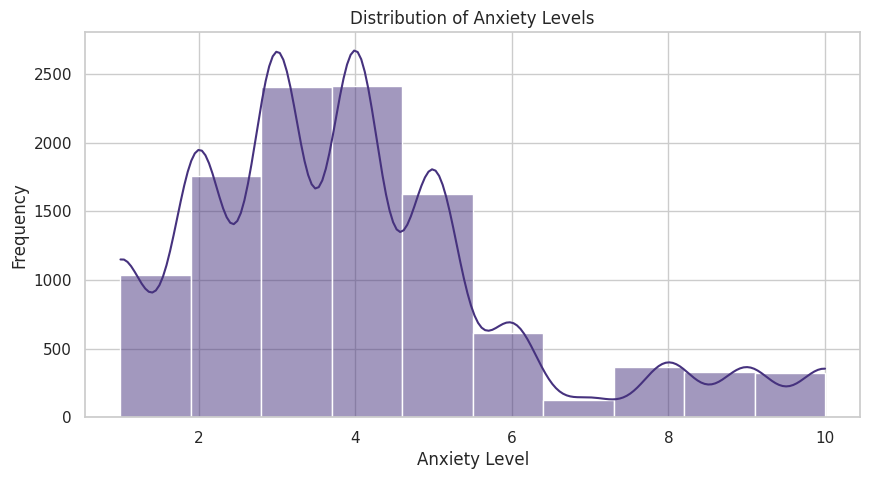

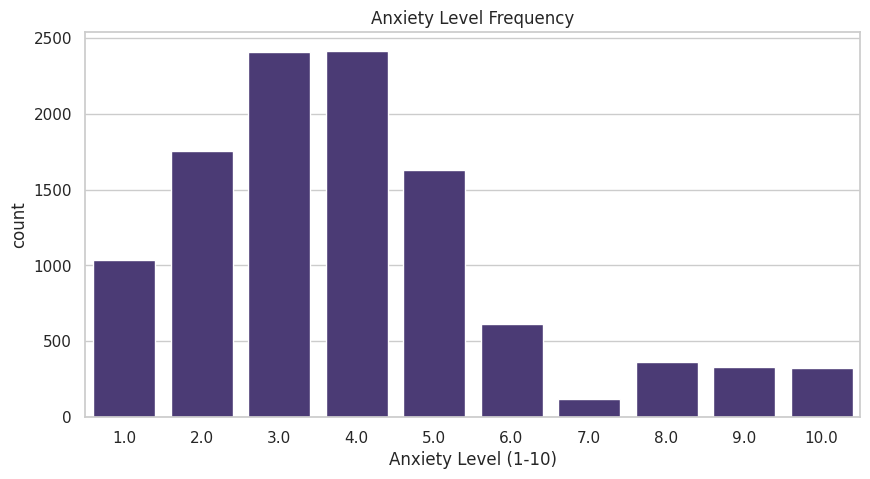

Target Statistics:


,Anxiety Level (1-10)
count,11000.000000
mean,3.929364
std,2.122533
min,1.000000
25%,2.000000
50%,4.000000
75%,5.000000
max,10.000000


Target Skewness: 1.0439964647889457
Target Kurtosis: 0.950053926739526


In [ ]:



TARGET = "Anxiety Level (1-10)"

plt.figure(figsize=(10, 5))

sns.histplot(
    df[TARGET],
    bins=10,
    kde=True
)

plt.title("Distribution of Anxiety Levels")
plt.xlabel("Anxiety Level")
plt.ylabel("Frequency")
plt.show()


plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x=TARGET,
    order=sorted(df[TARGET].dropna().unique())
)

plt.title("Anxiety Level Frequency")
plt.show()


print("Target Statistics:")
display(df[TARGET].describe())

print("Target Skewness:", df[TARGET].skew())
print("Target Kurtosis:", df[TARGET].kurtosis())


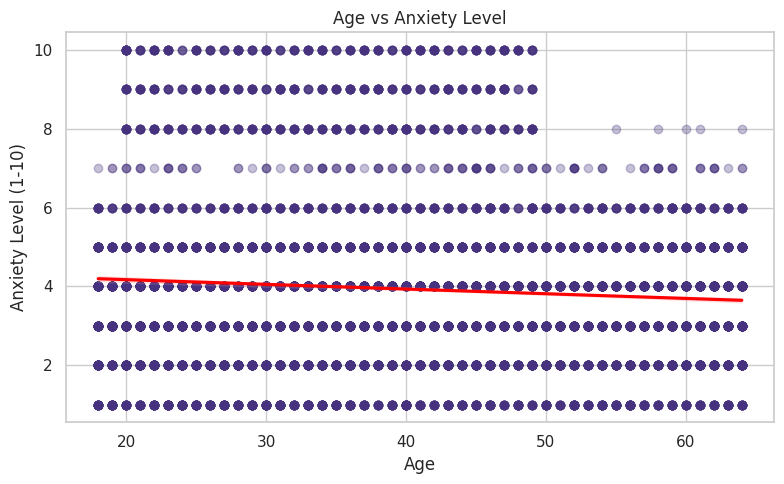

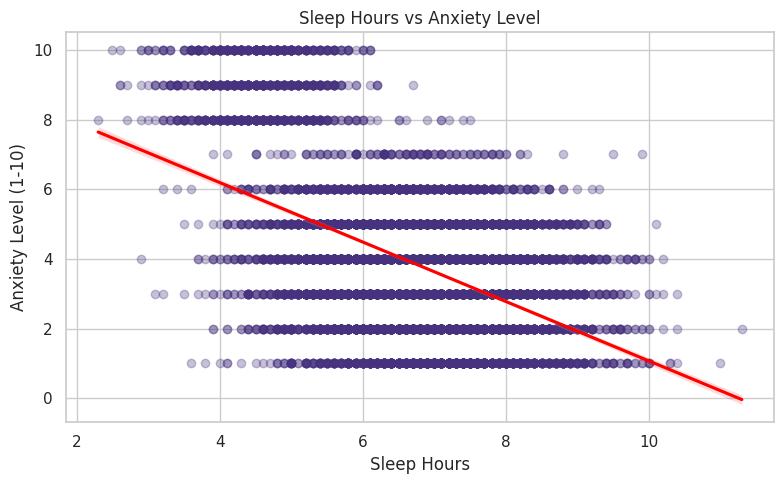

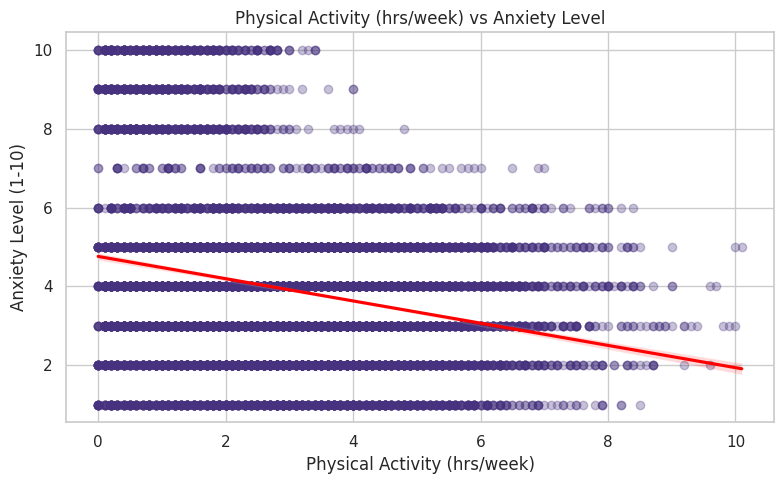

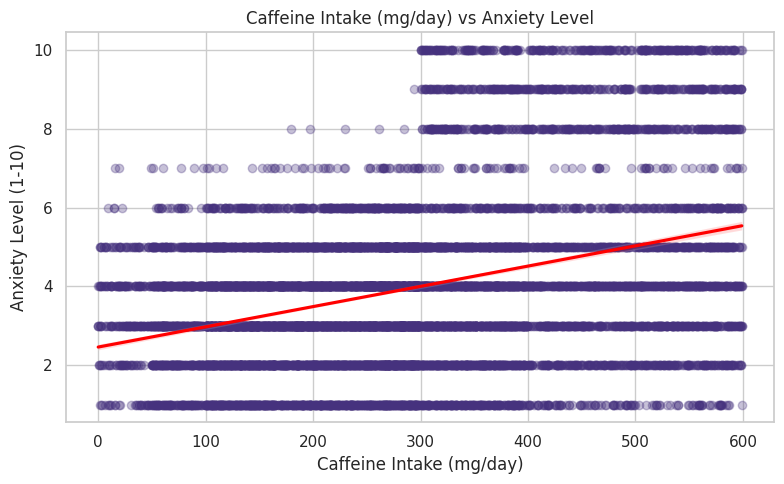

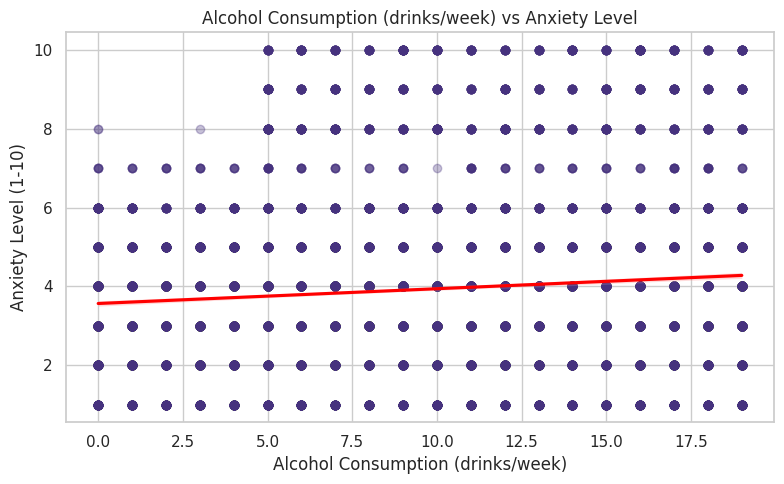

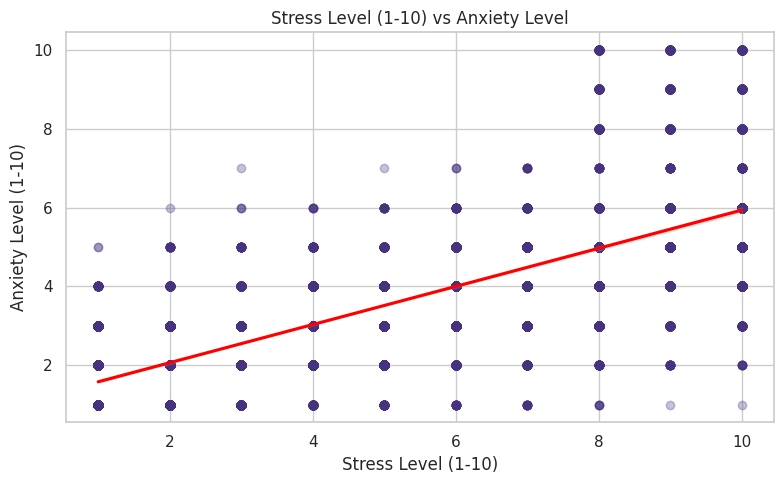

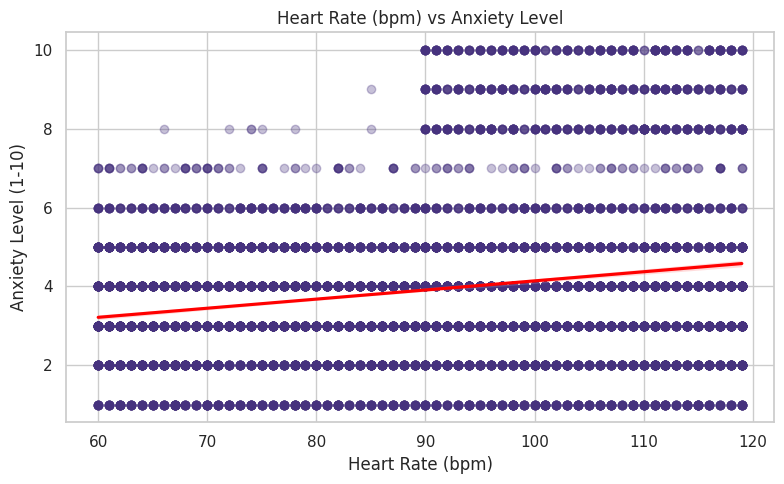

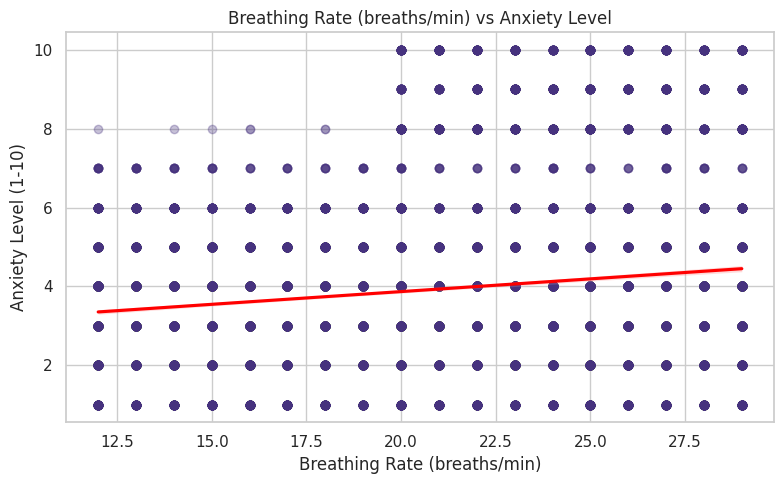

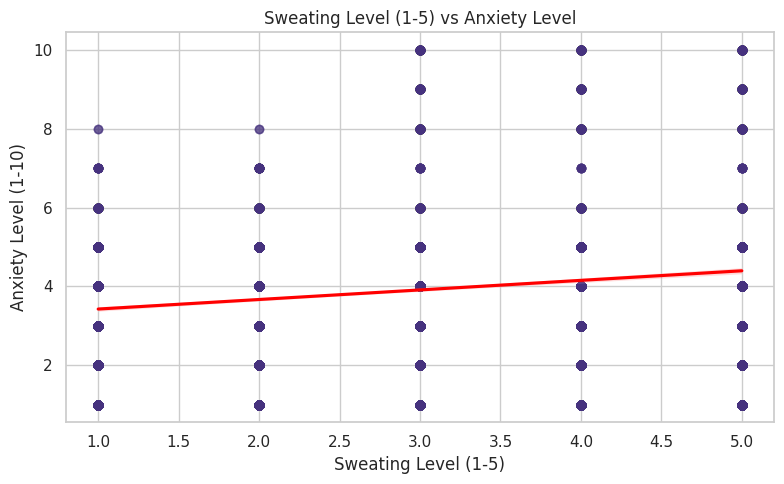

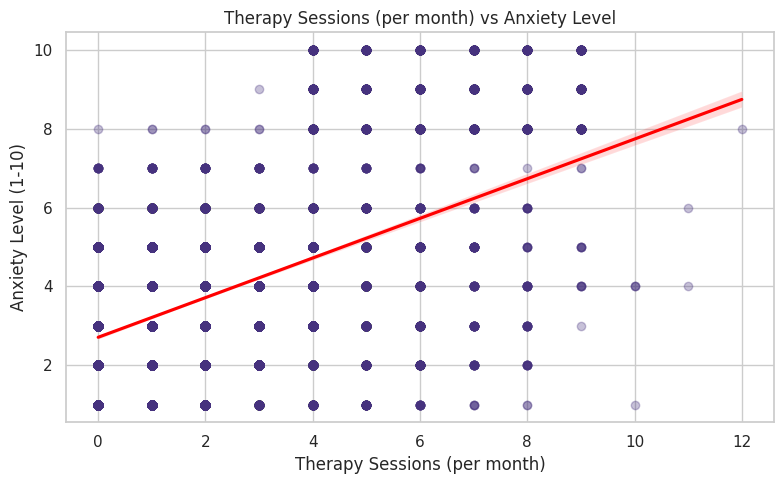

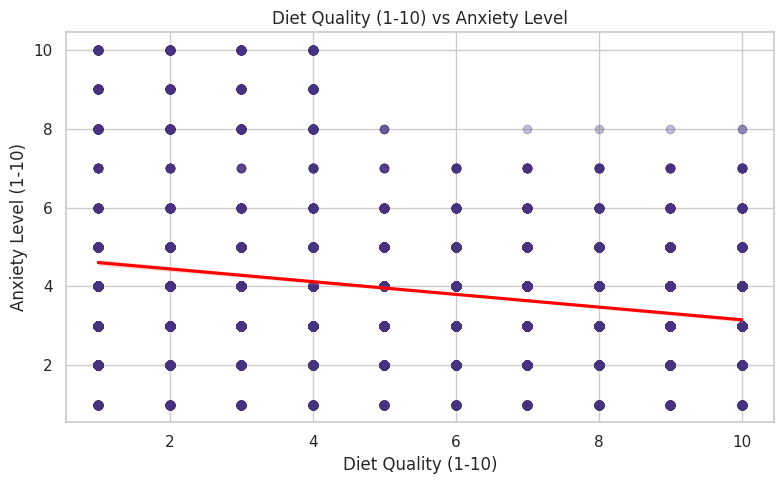

In [ ]:
for col in numerical_cols:

    if col == TARGET:
        continue

    plt.figure(figsize=(8, 5))

    sns.regplot(
        data=df,
        x=col,
        y=TARGET,
        scatter_kws={"alpha": 0.3},
        line_kws={"color": "red"}
    )

    plt.title(f"{col} vs Anxiety Level")
    plt.tight_layout()
    plt.show()


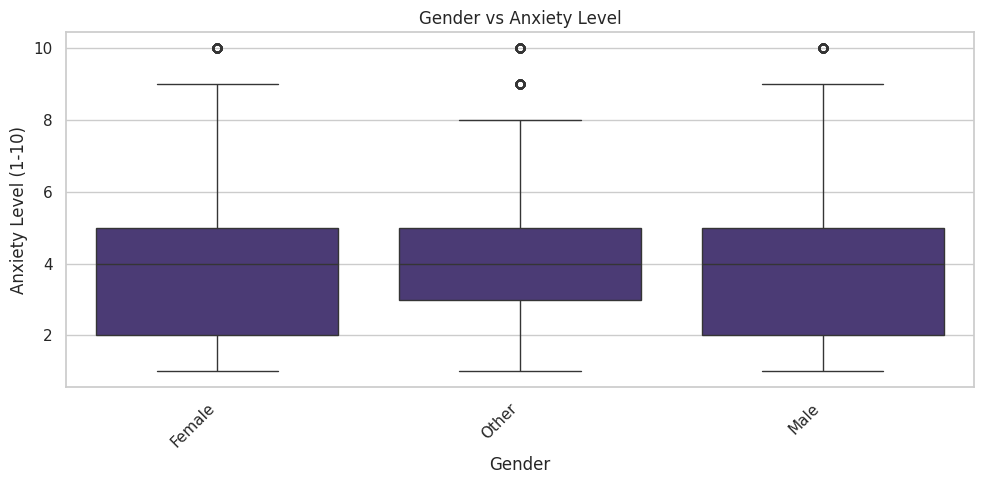


Mean Anxiety Level by Gender


,count,mean,median,std
Gender,,,,
Male,3657,3.933552,4.0,2.145861
Female,3730,3.931367,4.0,2.126240
Other,3613,3.923056,4.0,2.095360


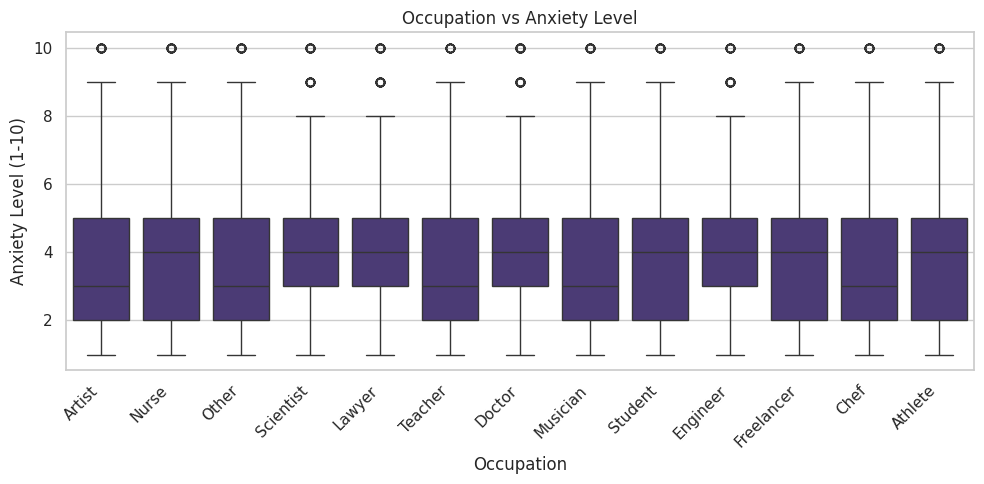


Mean Anxiety Level by Occupation


,count,mean,median,std
Occupation,,,,
Lawyer,809,4.206428,4.0,2.064710
Doctor,842,4.199525,4.0,2.174460
Engineer,833,4.138055,4.0,2.055458
Scientist,832,4.062500,4.0,2.087943
Freelancer,838,3.952267,4.0,2.152515
Student,878,3.883827,4.0,2.142620
Athlete,822,3.871046,4.0,2.146388
Nurse,861,3.854820,4.0,2.142280
Chef,858,3.840326,3.0,2.114882


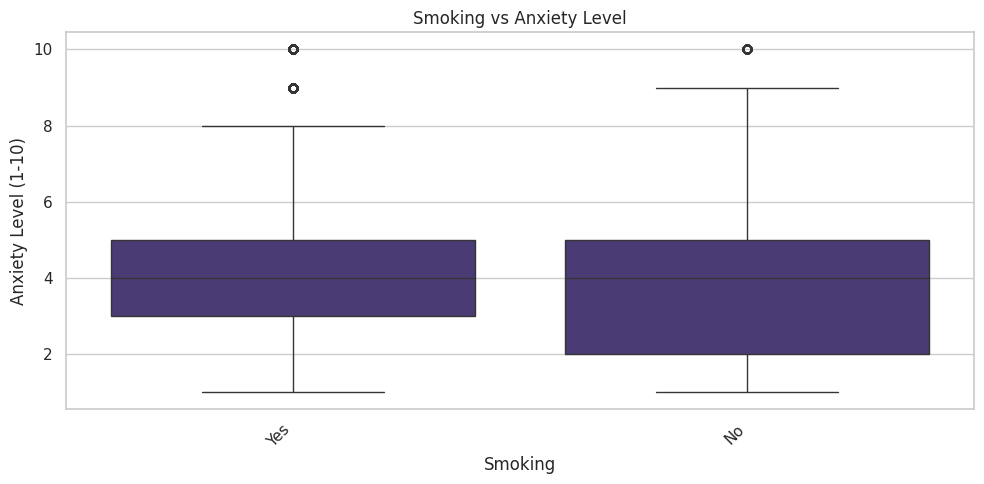


Mean Anxiety Level by Smoking


,count,mean,median,std
Smoking,,,,
Yes,5779,4.09448,4.0,2.270189
No,5221,3.74660,4.0,1.929890


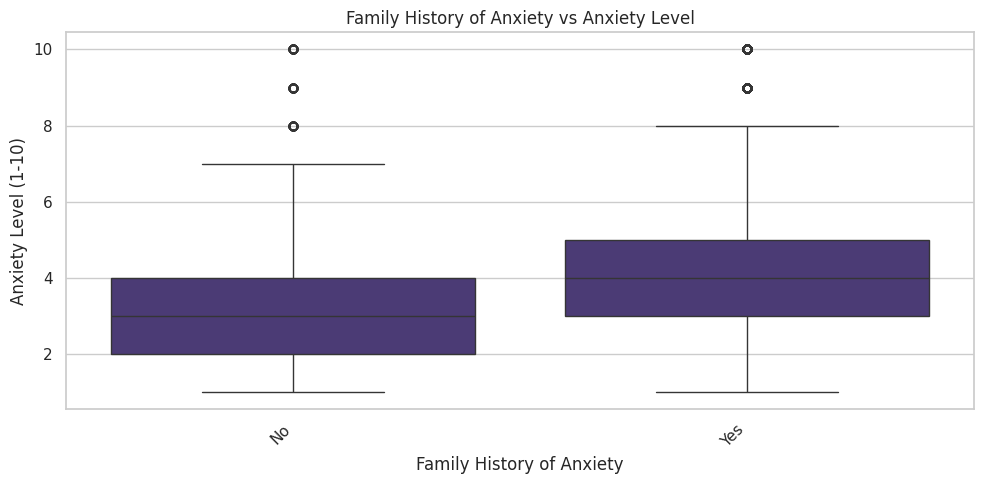


Mean Anxiety Level by Family History of Anxiety


,count,mean,median,std
Family History of Anxiety,,,,
Yes,5847,4.309731,4.0,2.294592
No,5153,3.497768,3.0,1.814699


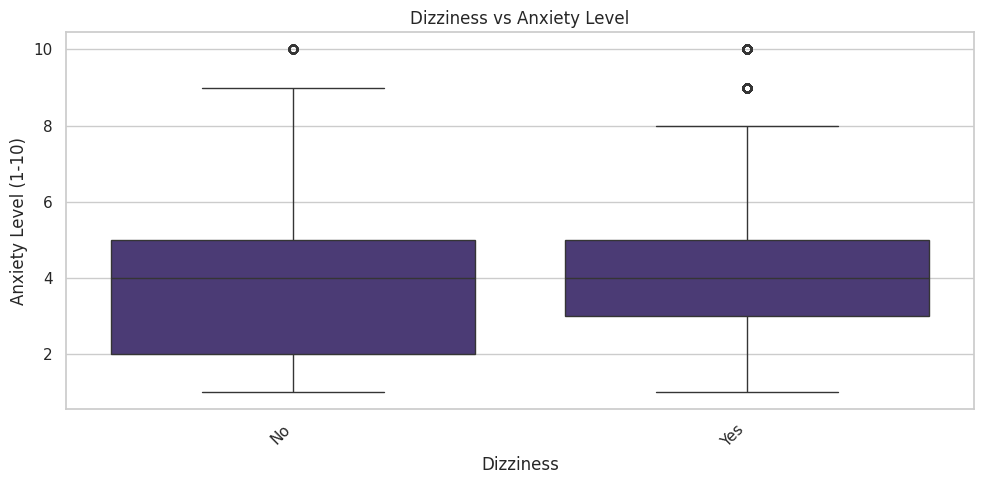


Mean Anxiety Level by Dizziness


,count,mean,median,std
Dizziness,,,,
Yes,5672,4.120769,4.0,2.294807
No,5328,3.725601,4.0,1.901400


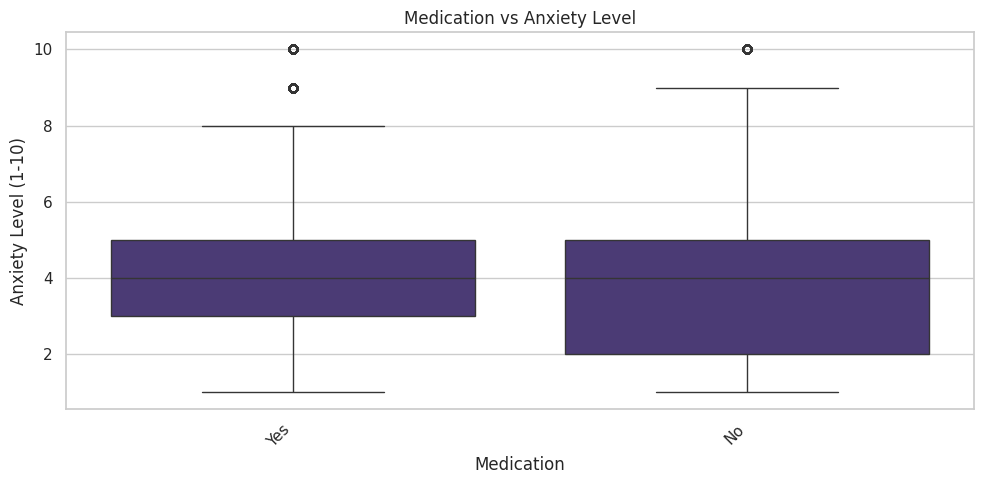


Mean Anxiety Level by Medication


,count,mean,median,std
Medication,,,,
Yes,5666,4.045711,4.0,2.193755
No,5334,3.805774,4.0,2.037101


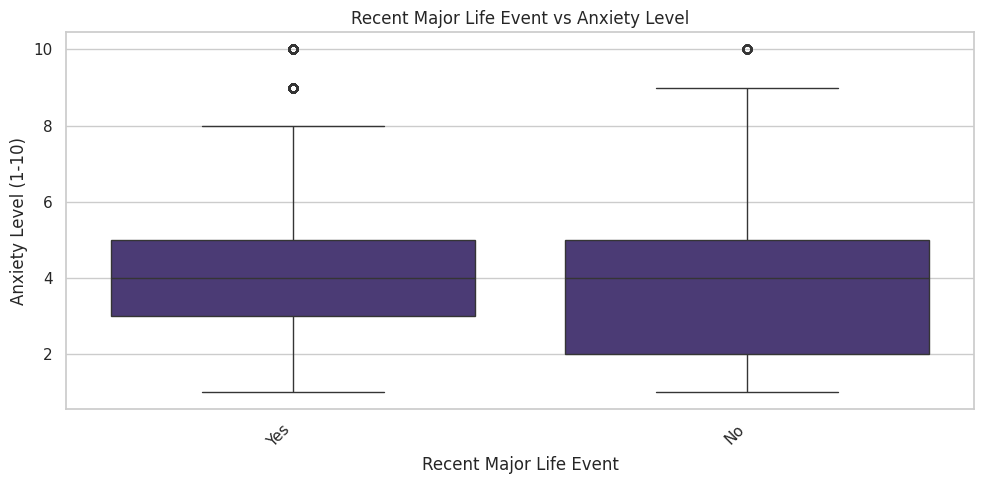


Mean Anxiety Level by Recent Major Life Event


,count,mean,median,std
Recent Major Life Event,,,,
Yes,5623,4.091766,4.0,2.280439
No,5377,3.759531,4.0,1.929374


In [ ]:


for col in categorical_cols:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=df,
        x=col,
        y=TARGET
    )

    plt.title(f"{col} vs Anxiety Level")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"\nMean Anxiety Level by {col}")
    display(
        df.groupby(col, observed=True)[TARGET]
        .agg(["count", "mean", "median", "std"])
        .sort_values("mean", ascending=False)
    )




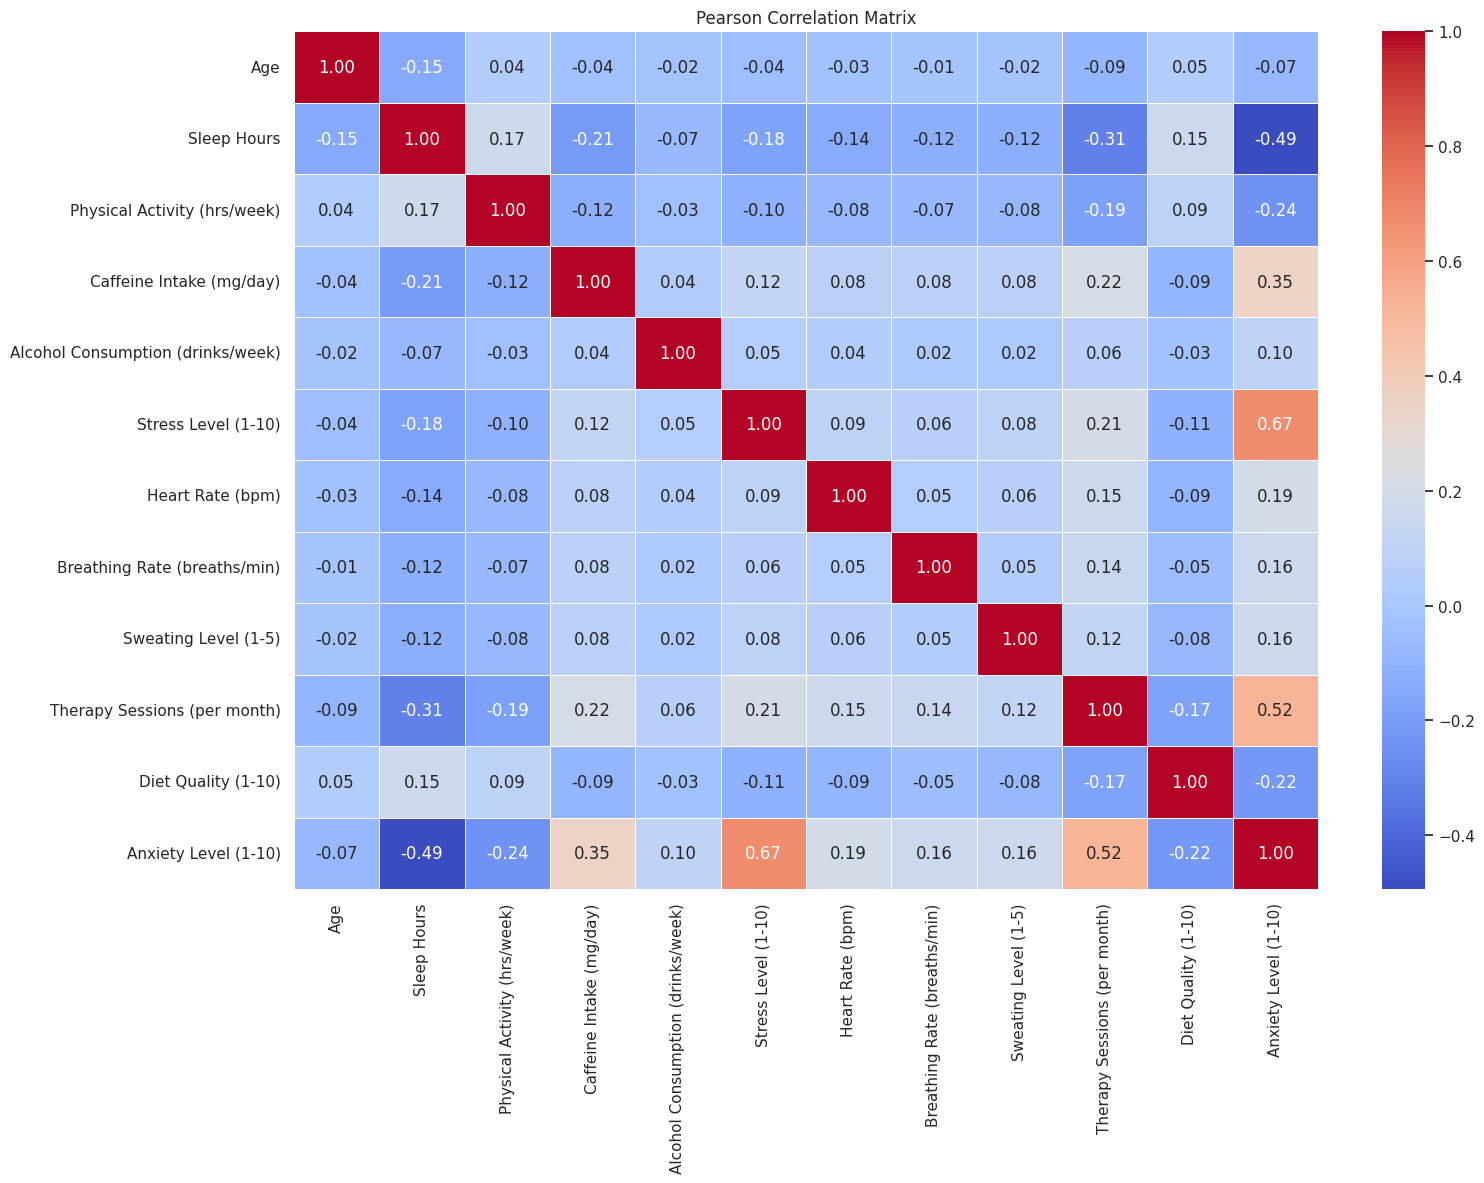

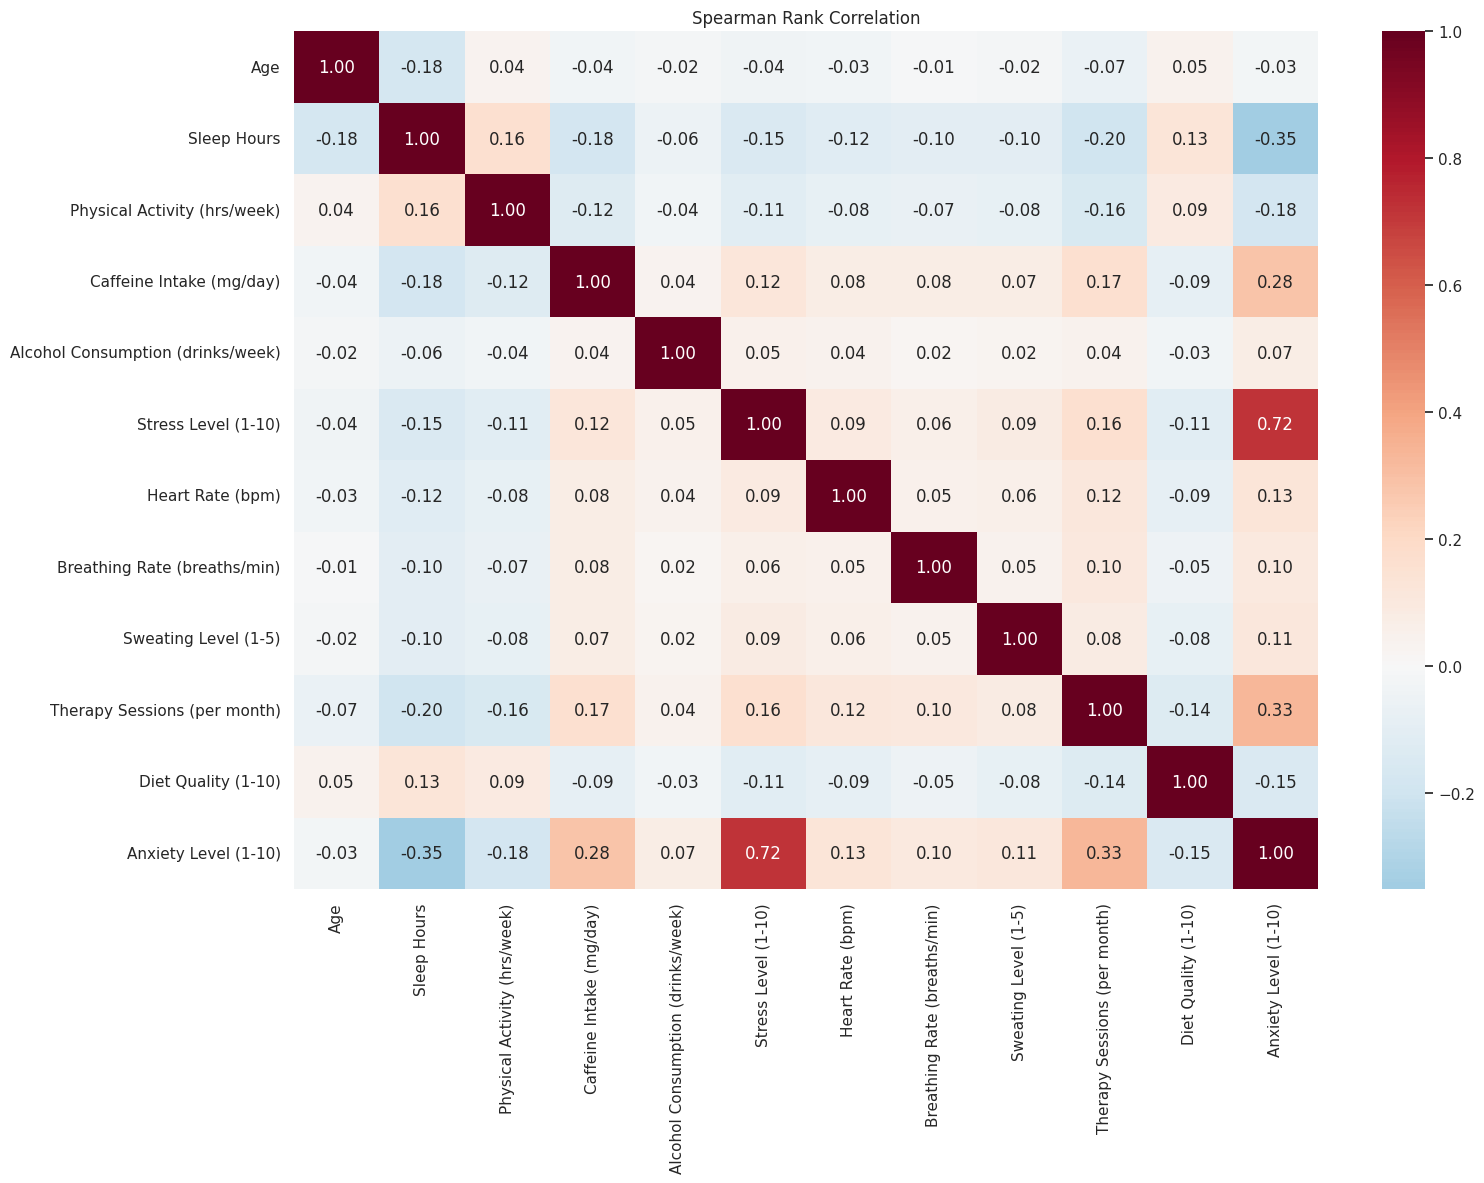


Correlation with Target:


,Correlation
Stress Level (1-10),0.667939
Therapy Sessions (per month),0.517606
Caffeine Intake (mg/day),0.350651
Heart Rate (bpm),0.188900
Sweating Level (1-5),0.160074
Breathing Rate (breaths/min),0.157048
Alcohol Consumption (drinks/week),0.100626
Age,-0.074316
Diet Quality (1-10),-0.220245
Physical Activity (hrs/week),-0.243187


In [ ]:
# ============================================================
# 10. CORRELATION ANALYSIS
# ============================================================

correlation_matrix = df[numerical_cols].corr(method="pearson")

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()


# Spearman Correlation

spearman_corr = df[numerical_cols].corr(method="spearman")

plt.figure(figsize=(16, 12))

sns.heatmap(
    spearman_corr,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f"
)

plt.title("Spearman Rank Correlation")
plt.tight_layout()
plt.show()


print("\nCorrelation with Target:")

display(
    correlation_matrix[TARGET]
    .drop(TARGET)
    .sort_values(ascending=False)
    .to_frame("Correlation")
)


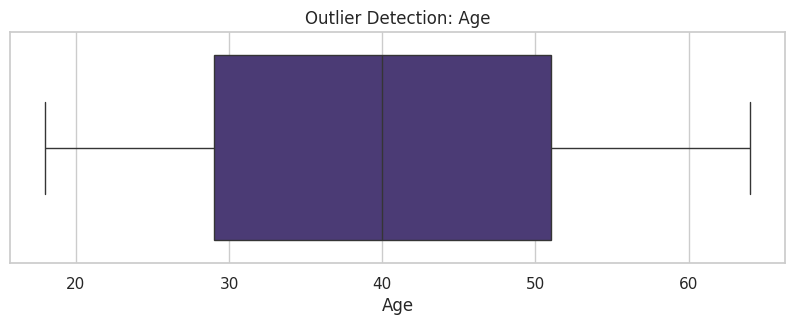

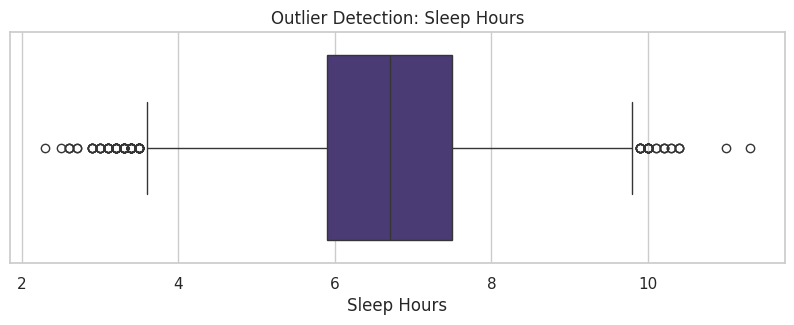

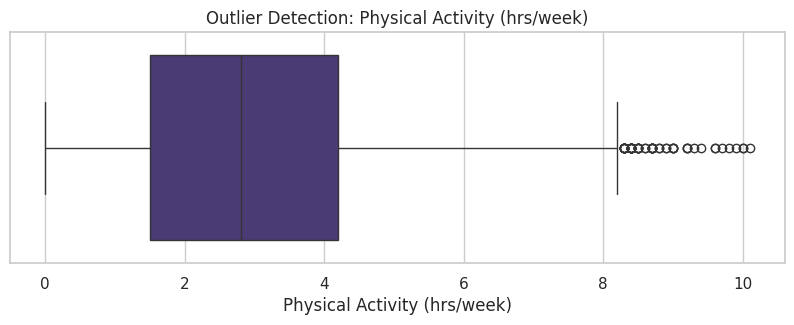

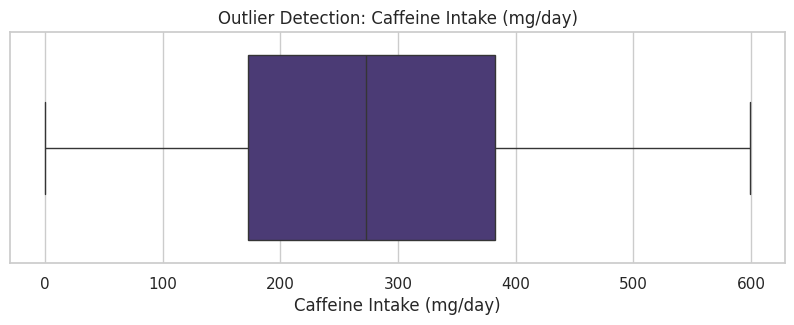

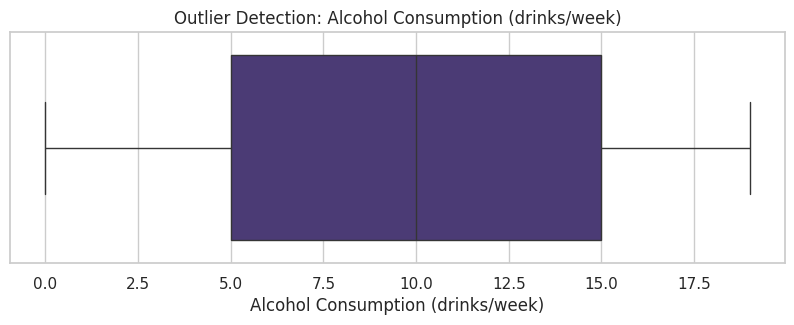

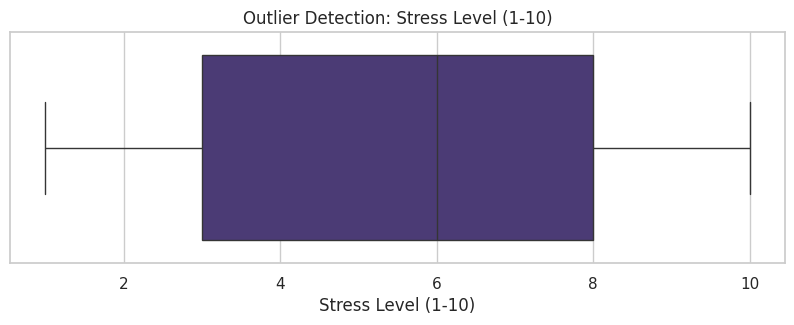

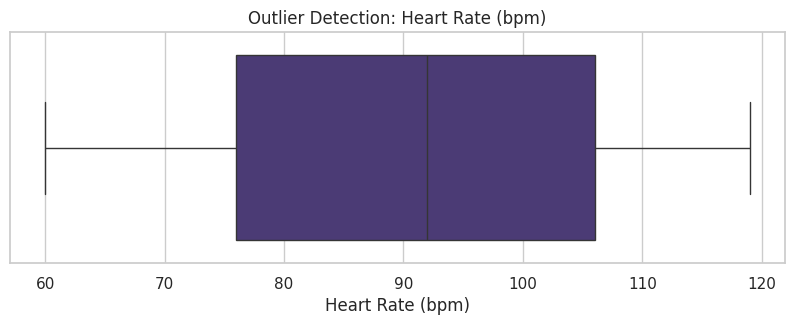

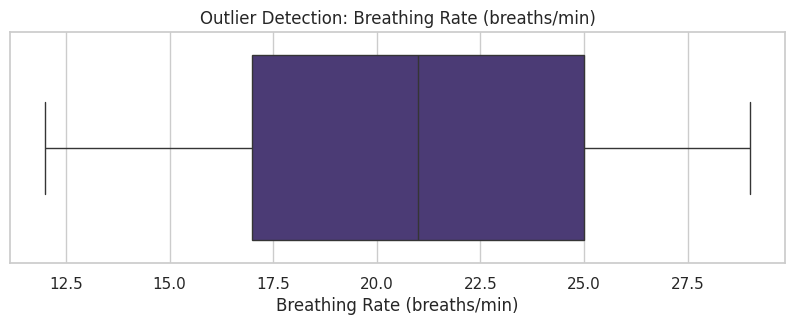

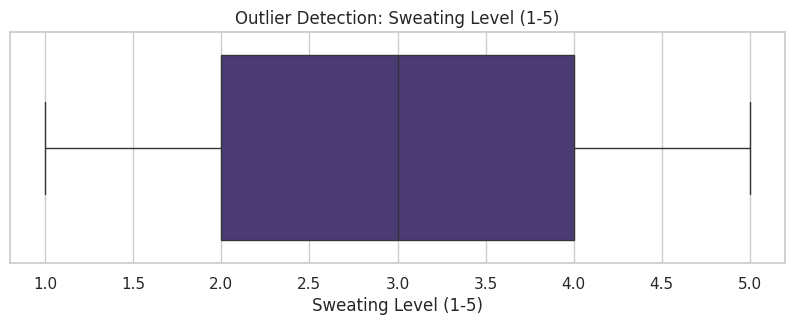

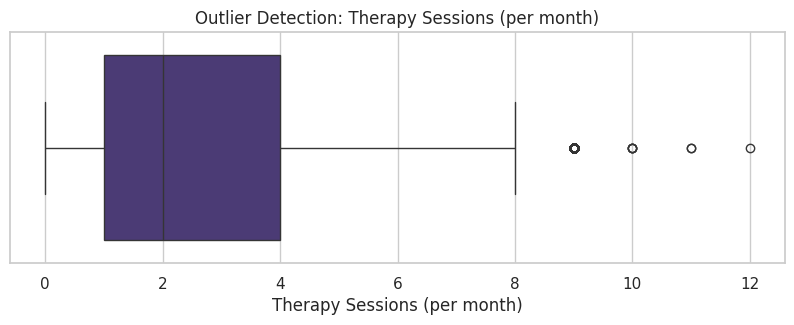

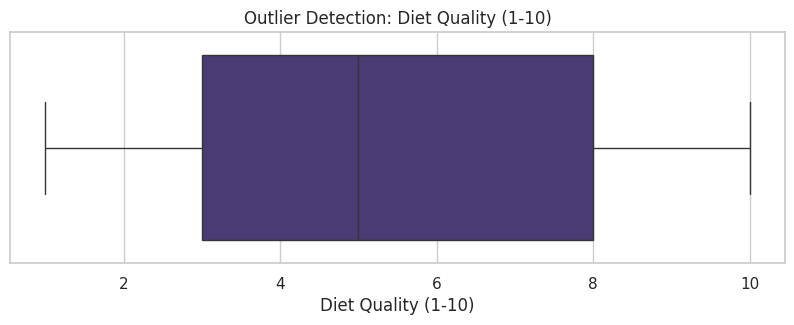

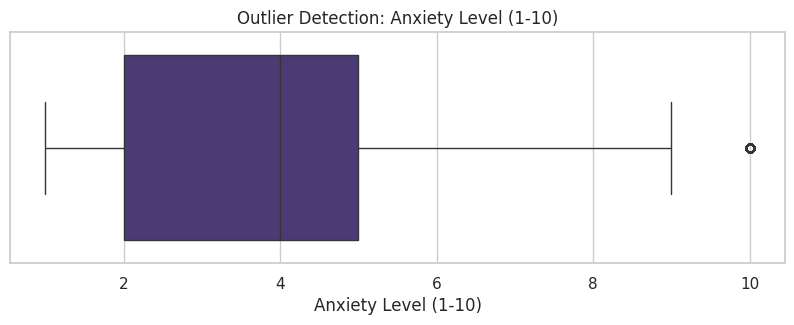

In [ ]:
# ============================================================
# 11. OUTLIER DETECTION - BOXPLOTS
# ============================================================

for col in numerical_cols:

    plt.figure(figsize=(10, 3))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Detection: {col}")
    plt.show()

In [ ]:
# ============================================================
# 12. IQR OUTLIER ANALYSIS
# ============================================================

outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": len(outliers) / len(df) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df)


,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Age,-4.00,84.00,0,0.000000
1,Sleep Hours,3.50,9.90,110,1.000000
2,Physical Activity (hrs/week),-2.55,8.25,56,0.509091
3,Caffeine Intake (mg/day),-143.00,697.00,0,0.000000
4,Alcohol Consumption (drinks/week),-10.00,30.00,0,0.000000
5,Stress Level (1-10),-4.50,15.50,0,0.000000
6,Heart Rate (bpm),31.00,151.00,0,0.000000
7,Breathing Rate (breaths/min),5.00,37.00,0,0.000000
8,Sweating Level (1-5),-1.00,7.00,0,0.000000
9,Therapy Sessions (per month),-3.50,8.50,178,1.618182


In [ ]:
# ============================================================
# 13. STATISTICAL DISTRIBUTION ANALYSIS
# ============================================================

distribution_results = []

for col in numerical_cols:

    values = df[col].dropna()

    distribution_results.append({
        "Feature": col,
        "Mean": values.mean(),
        "Median": values.median(),
        "Mode": values.mode().iloc[0],
        "Variance": values.var(),
        "Std_Deviation": values.std(),
        "Skewness": stats.skew(values),
        "Kurtosis": stats.kurtosis(values)
    })

distribution_df = pd.DataFrame(distribution_results)

display(distribution_df)

,Feature,Mean,Median,Mode,Variance,Std_Deviation,Skewness,Kurtosis
0,Age,40.241727,40.0,30.0,175.195404,13.236140,0.097323,-1.126374
1,Sleep Hours,6.650691,6.7,6.7,1.506778,1.227509,-0.224442,-0.048092
2,Physical Activity (hrs/week),2.942136,2.8,1.9,3.340946,1.827825,0.506941,-0.215525
3,Caffeine Intake (mg/day),286.090000,273.0,294.0,20970.850341,144.813157,0.323897,-0.701673
4,Alcohol Consumption (drinks/week),9.701636,10.0,9.0,32.372831,5.689713,-0.023331,-1.159199
5,Stress Level (1-10),5.856364,6.0,10.0,8.568511,2.927202,-0.160850,-1.255706
6,Heart Rate (bpm),90.916000,92.0,112.0,300.180597,17.325721,-0.119188,-1.192627
7,Breathing Rate (breaths/min),20.957545,21.0,26.0,26.626709,5.160107,-0.141186,-1.171878
8,Sweating Level (1-5),3.080636,3.0,5.0,1.956857,1.398877,-0.073919,-1.263197
9,Therapy Sessions (per month),2.427818,2.0,1.0,4.765950,2.183106,1.034975,0.586111


In [ ]:

# ============================================================
# 14. NORMALITY TEST
# ============================================================

normality_results = []

for col in numerical_cols:

    values = df[col].dropna()

    sample = values.sample(
        min(len(values), 5000),
        random_state=RANDOM_STATE
    )

    statistic, p_value = stats.normaltest(sample)

    normality_results.append({
        "Feature": col,
        "Statistic": statistic,
        "P_Value": p_value,
        "Normally_Distributed": p_value > 0.05
    })

display(pd.DataFrame(normality_results))

,Feature,Statistic,P_Value,Normally_Distributed
0,Age,2299.238317,0.000000e+00,False
1,Sleep Hours,32.088526,1.076627e-07,False
2,Physical Activity (hrs/week),210.602231,1.854841e-46,False
3,Caffeine Intake (mg/day),354.421267,1.092445e-77,False
4,Alcohol Consumption (drinks/week),3078.188096,0.000000e+00,False
5,Stress Level (1-10),7742.382921,0.000000e+00,False
6,Heart Rate (bpm),4061.620166,0.000000e+00,False
7,Breathing Rate (breaths/min),3335.977803,0.000000e+00,False
8,Sweating Level (1-5),7899.026603,0.000000e+00,False
9,Therapy Sessions (per month),660.707622,3.381916e-144,False


In [ ]:
df.columns = df.columns.str.strip()

for col in df.select_dtypes(include="object"):
    df[col] = df[col].str.strip()

df.replace(["", " ", "NA", "N/A", "null", "None"], np.nan, inplace=True)

df.drop_duplicates(inplace=True)

df.drop(columns=constant_columns, errors="ignore", inplace=True)

print("Shape after cleaning:", df.shape)

Shape after cleaning: (11000, 19)


In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.impute import SimpleImputer

vif_data = df[numerical_cols].drop(columns=[TARGET])

vif_data = pd.DataFrame(
    SimpleImputer(strategy="median").fit_transform(vif_data),
    columns=vif_data.columns
)

vif_results = pd.DataFrame()

vif_results["Feature"] = vif_data.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_data.values,
        i
    )
    for i in range(vif_data.shape[1])
]

display(vif_results.sort_values("VIF", ascending=False))

,Feature,VIF
1,Sleep Hours,1.238787
9,Therapy Sessions (per month),1.233869
3,Caffeine Intake (mg/day),1.088100
5,Stress Level (1-10),1.078829
2,Physical Activity (hrs/week),1.065961
10,Diet Quality (1-10),1.056722
0,Age,1.054387
6,Heart Rate (bpm),1.043640
7,Breathing Rate (breaths/min),1.031229
8,Sweating Level (1-5),1.031178


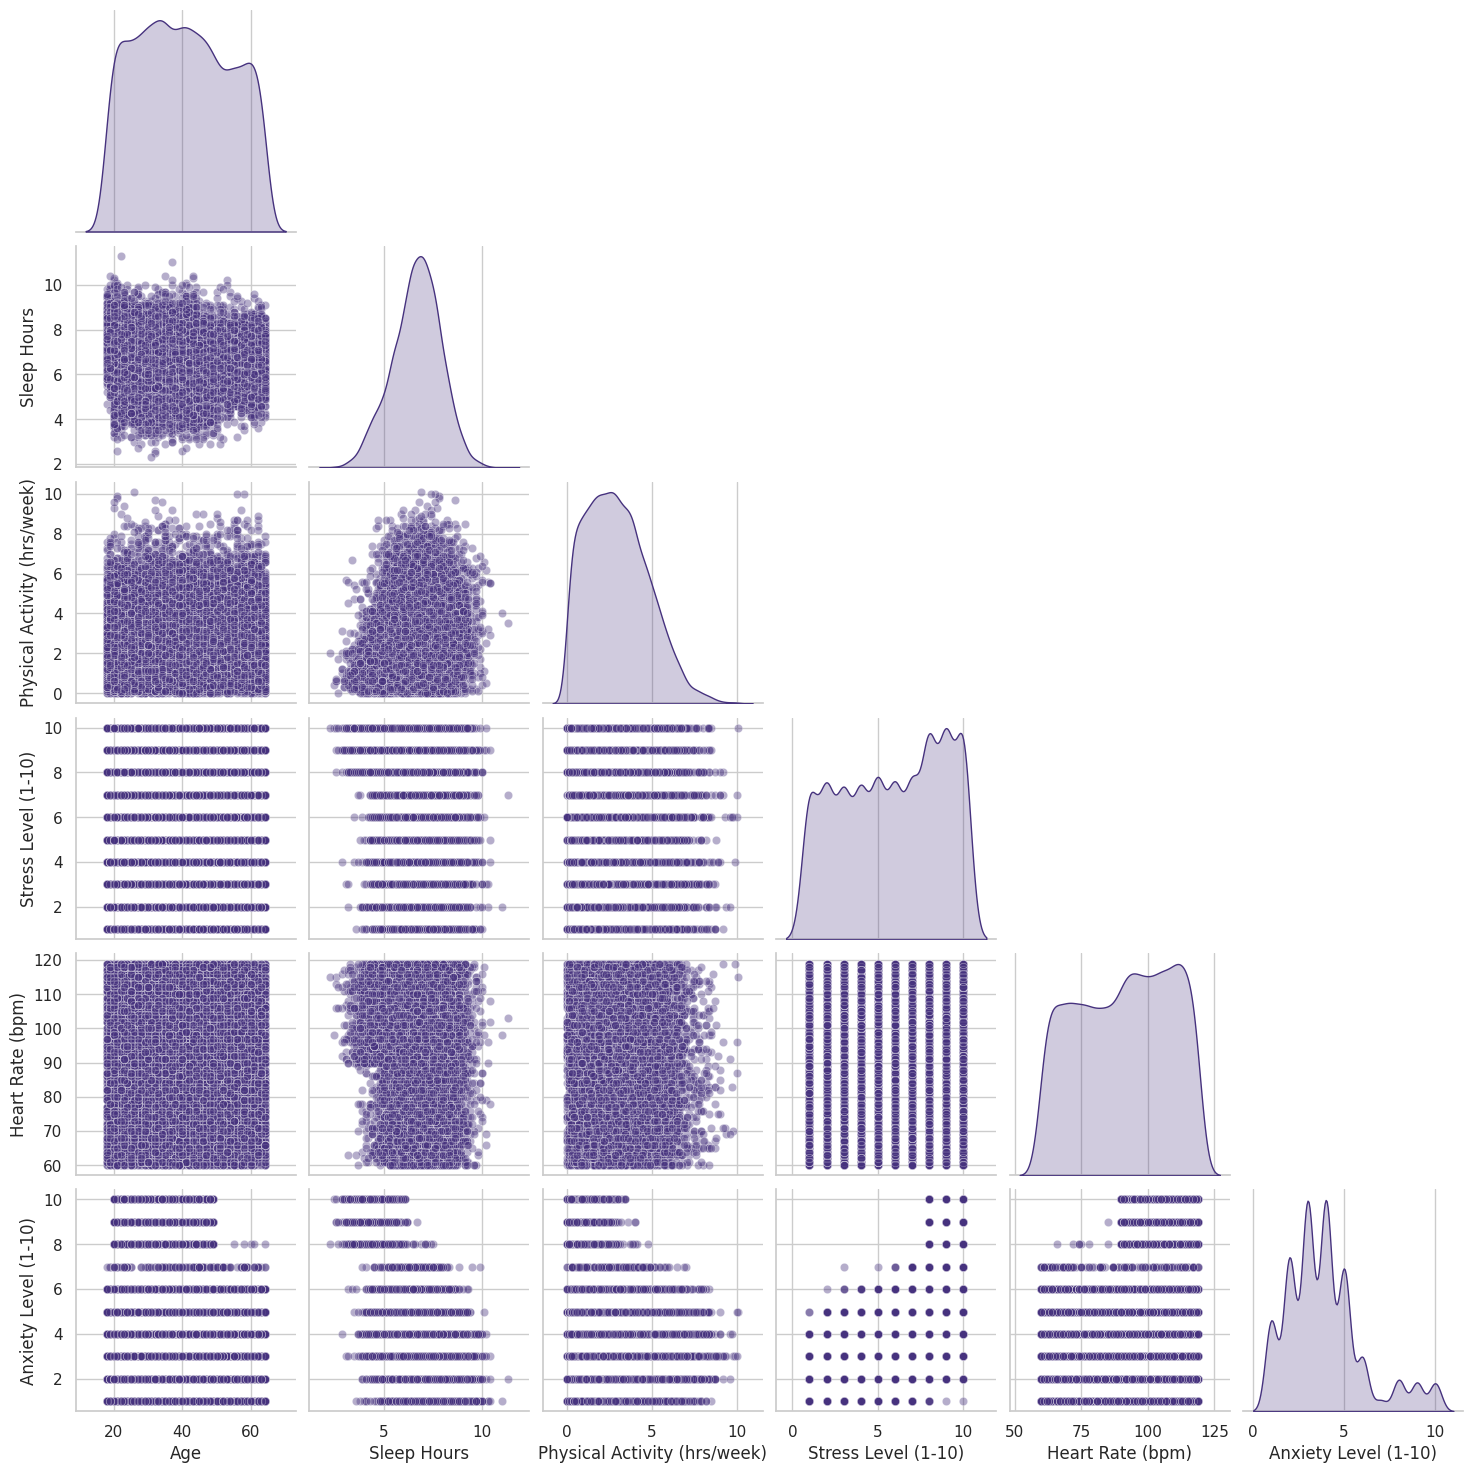

In [ ]:
selected_features = [
    "Age",
    "Sleep Hours",
    "Physical Activity (hrs/week)",
    "Stress Level (1-10)",
    "Heart Rate (bpm)",
    "Anxiety Level (1-10)"
]

sns.pairplot(
    df[selected_features],
    corner=True,
    diag_kind="kde",
    plot_kws={"alpha": 0.4}
)

plt.show()

In [ ]:

group_features = [
    "Gender",
    "Occupation",
    "Smoking",
    "Family History of Anxiety",
    "Dizziness",
    "Medication",
    "Recent Major Life Event"
]

for col in group_features:

    result = df.groupby(col, observed=True)[TARGET].agg(
        ["count", "mean", "median", "std"]
    )

    print(f"\nAnalysis by {col}")
    display(result.sort_values("mean", ascending=False))


Analysis by Gender


,count,mean,median,std
Gender,,,,
Male,3657,3.933552,4.0,2.145861
Female,3730,3.931367,4.0,2.126240
Other,3613,3.923056,4.0,2.095360



Analysis by Occupation


,count,mean,median,std
Occupation,,,,
Lawyer,809,4.206428,4.0,2.064710
Doctor,842,4.199525,4.0,2.174460
Engineer,833,4.138055,4.0,2.055458
Scientist,832,4.062500,4.0,2.087943
Freelancer,838,3.952267,4.0,2.152515
Student,878,3.883827,4.0,2.142620
Athlete,822,3.871046,4.0,2.146388
Nurse,861,3.854820,4.0,2.142280
Chef,858,3.840326,3.0,2.114882



Analysis by Smoking


,count,mean,median,std
Smoking,,,,
Yes,5779,4.09448,4.0,2.270189
No,5221,3.74660,4.0,1.929890


... (4 outputs left out)


Analysis by Medication


,count,mean,median,std
Medication,,,,
Yes,5666,4.045711,4.0,2.193755
No,5334,3.805774,4.0,2.037101



Analysis by Recent Major Life Event


,count,mean,median,std
Recent Major Life Event,,,,
Yes,5623,4.091766,4.0,2.280439
No,5377,3.759531,4.0,1.929374


In [ ]:
df_processed = df.copy()

# Sleep Category

df_processed["Sleep Category"] = pd.cut(
    df_processed["Sleep Hours"],
    bins=[-np.inf, 5, 7, 9, np.inf],
    labels=["Very Low", "Low", "Optimal", "High"]
)

# Physical Activity Category

df_processed["Activity Category"] = pd.cut(
    df_processed["Physical Activity (hrs/week)"],
    bins=[-np.inf, 1, 3, 6, np.inf],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Caffeine Category

df_processed["Caffeine Category"] = pd.cut(
    df_processed["Caffeine Intake (mg/day)"],
    bins=[-np.inf, 100, 200, 400, np.inf],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Alcohol Category

df_processed["Alcohol Category"] = pd.cut(
    df_processed["Alcohol Consumption (drinks/week)"],
    bins=[-np.inf, 0, 3, 7, np.inf],
    labels=["None", "Low", "Moderate", "High"]
)

# Stress Category

df_processed["Stress Category"] = pd.cut(
    df_processed["Stress Level (1-10)"],
    bins=[0, 3, 6, 10],
    labels=["Low", "Moderate", "High"]
)

# Diet Category

df_processed["Diet Category"] = pd.cut(
    df_processed["Diet Quality (1-10)"],
    bins=[0, 3, 6, 10],
    labels=["Poor", "Moderate", "Good"]
)

# Physiological Indicator

df_processed["Heart Rate per Age"] = (
    df_processed["Heart Rate (bpm)"] /
    df_processed["Age"].replace(0, np.nan)
)

print("Feature Engineered Dataset:")
display(df_processed.head())


Feature Engineered Dataset:


,Age,Gender,Occupation,Sleep Hours,Physical Activity (hrs/week),Caffeine Intake (mg/day),Alcohol Consumption (drinks/week),Smoking,Family History of Anxiety,Stress Level (1-10),...,Recent Major Life Event,Diet Quality (1-10),Anxiety Level (1-10),Sleep Category,Activity Category,Caffeine Category,Alcohol Category,Stress Category,Diet Category,Heart Rate per Age
0,29,Female,Artist,6.0,2.7,181,10,Yes,No,10,...,Yes,7,5.0,Low,Moderate,Moderate,High,High,Good,3.931034
1,46,Other,Nurse,6.2,5.7,200,8,Yes,Yes,1,...,No,8,3.0,Low,High,Moderate,High,Low,Good,1.347826
2,64,Male,Other,5.0,3.7,117,4,No,Yes,1,...,Yes,1,1.0,Very Low,High,Moderate,Moderate,Low,Poor,1.421875
3,20,Female,Scientist,5.8,2.8,360,6,Yes,No,4,...,No,1,2.0,Low,Moderate,High,Moderate,Moderate,Poor,4.300000
4,49,Female,Other,8.2,2.3,247,4,Yes,No,1,...,No,3,1.0,Optimal,Moderate,High,Moderate,Low,Poor,2.000000


In [ ]:
numeric_features = df_processed.drop(
    columns=[TARGET]
).select_dtypes(include=np.number).columns.tolist()

categorical_features = df_processed.drop(
    columns=[TARGET]
).select_dtypes(include=["object", "category"]).columns.tolist()

numeric_imputer = SimpleImputer(strategy="median")

categorical_imputer = SimpleImputer(strategy="most_frequent")

df_processed[numeric_features] = numeric_imputer.fit_transform(
    df_processed[numeric_features]
)

df_processed[categorical_features] = categorical_imputer.fit_transform(
    df_processed[categorical_features]
)

In [ ]:
df_model = df_processed.copy()

for col in numeric_features:

    Q1 = df_model[col].quantile(0.25)
    Q3 = df_model[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_model[col] = df_model[col].clip(
        lower=lower,
        upper=upper
    )

In [ ]:
X = df_model.drop(columns=[TARGET])
y = df_model[TARGET]

print("Feature Matrix Shape:", X.shape)
print("Target Shape:", y.shape)


Feature Matrix Shape: (11000, 25)
Target Shape: (11000,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (8800, 25)
Testing Data: (2200, 25)


In [ ]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (8800, 60)
Processed Testing Shape: (2200, 60)


,Feature,Mutual_Information
5,numerical__Stress Level (1-10),0.361662
54,categorical__Stress Category_High,0.260908
55,categorical__Stress Category_Low,0.199380
1,numerical__Sleep Hours,0.180334
9,numerical__Therapy Sessions (per month),0.175039
41,categorical__Sleep Category_Very Low,0.139093
3,numerical__Caffeine Intake (mg/day),0.089770
2,numerical__Physical Activity (hrs/week),0.073524
10,numerical__Diet Quality (1-10),0.067113
56,categorical__Stress Category_Moderate,0.066668


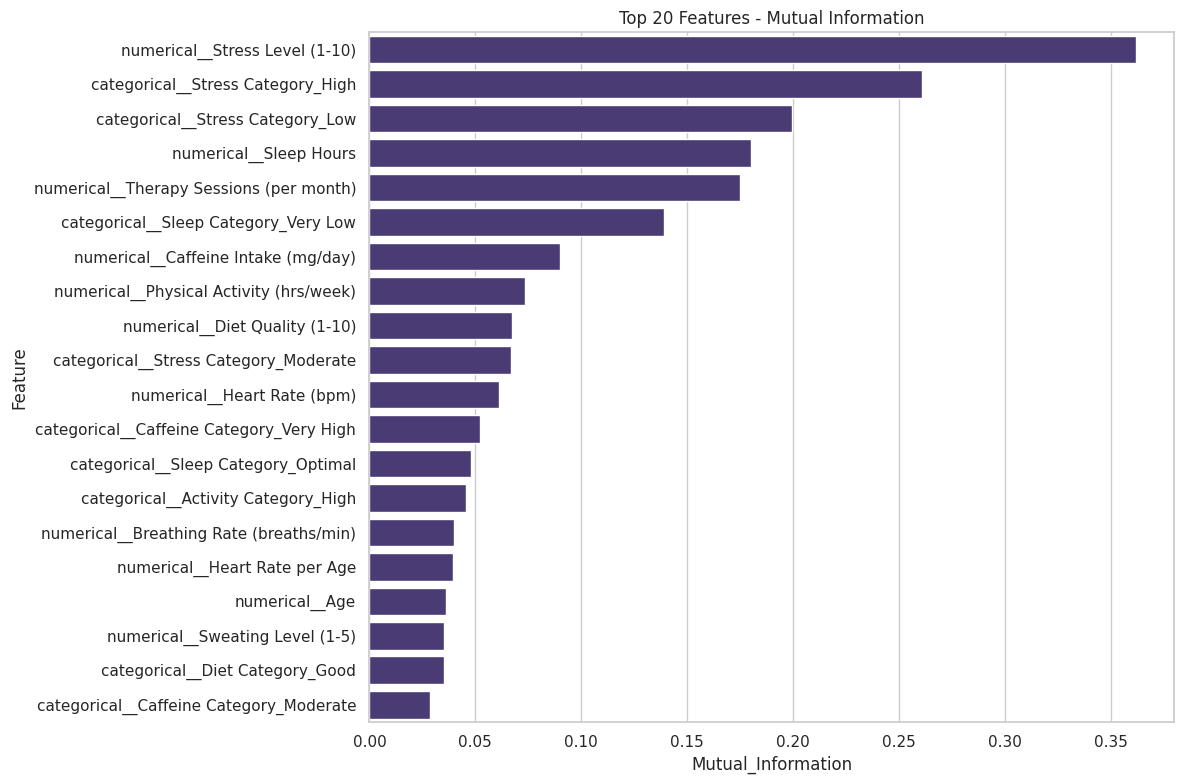

In [ ]:

feature_selector = SelectKBest(
    score_func=mutual_info_regression,
    k="all"
)

feature_selector.fit(X_train_processed, y_train)

try:
    encoded_feature_names = preprocessor.get_feature_names_out()
except:
    encoded_feature_names = np.array([
        f"Feature_{i}"
        for i in range(X_train_processed.shape[1])
    ])

feature_importance = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Mutual_Information": feature_selector.scores_
})

feature_importance.sort_values(
    "Mutual_Information",
    ascending=False,
    inplace=True
)

display(feature_importance)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=feature_importance.head(20),
    x="Mutual_Information",
    y="Feature"
)

plt.title("Top 20 Features - Mutual Information")
plt.tight_layout()
plt.show()

In [ ]:
pca = PCA(n_components=0.95, random_state=RANDOM_STATE)

X_train_pca = pca.fit_transform(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_pca = pca.transform(
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("Original Features:", X_train_processed.shape[1])
print("PCA Features:", X_train_pca.shape[1])

print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_.sum()
)


Original Features: 60
PCA Features: 29
Explained Variance Ratio: 0.9526680906418221


In [ ]:

df_processed.to_csv(
    "anxiety_dataset_cleaned.csv",
    index=False
)

df_model.to_csv(
    "anxiety_dataset_model_ready.csv",
    index=False
)

print("Preprocessing Completed Successfully.")

Preprocessing Completed Successfully.
